# Practical Application III: Comparing Classifiers

**Overview**: In this practical application, your goal is to compare the performance of the classifiers we encountered in this section, namely K Nearest Neighbor, Logistic Regression, Decision Trees, and Support Vector Machines.  We will utilize a dataset related to marketing bank products over the telephone.  



### Getting Started

Our dataset comes from the UCI Machine Learning repository [link](https://archive.ics.uci.edu/ml/datasets/bank+marketing).  The data is from a Portugese banking institution and is a collection of the results of multiple marketing campaigns.  We will make use of the article accompanying the dataset [here](CRISP-DM-BANK.pdf) for more information on the data and features.



### Problem 1: Understanding the Data

To gain a better understanding of the data, please read the information provided in the UCI link above, and examine the **Materials and Methods** section of the paper.  How many marketing campaigns does this data represent?

**Answer:** According to the *Materials and Methods* section of the accompanying paper (Moro et al., 2014), the data comes from **17 telemarketing campaigns** run by a Portuguese bank between **May 2008 and November 2010**. Those campaigns made 79,354 contacts in total. Each campaign offered clients a long-term **term deposit** with a good interest rate.

The version used here (`bank-additional-full.csv`) has **41,188 contacts**. It adds five social and economic context features, such as the Euribor rate and the employment variation rate.

### Problem 2: Read in the Data

Use pandas to read in the dataset `bank-additional-full.csv` and assign to a meaningful variable name.

In [ ]:
# Core data-analysis libraries
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# scikit-learn: preprocessing, models, model selection and metrics
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
RANDOM_STATE = 42

# Key figures are also saved to images/ so the README can show them
IMAGE_DIR = Path('images')
IMAGE_DIR.mkdir(exist_ok=True)

def save_fig(name):
    """Save the current figure to the images folder for use in the README."""
    plt.savefig(IMAGE_DIR / f'{name}.png', dpi=110, bbox_inches='tight')

In [ ]:
# The file is semicolon-delimited
df = pd.read_csv('data/bank-additional-full.csv', sep=';')

In [ ]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


### Problem 3: Understanding the Features


Examine the data description below, and determine if any of the features are missing values or need to be coerced to a different data type.


```
Input variables:
# bank client data:
1 - age (numeric)
2 - job : type of job (categorical: 'admin.','blue-collar','entrepreneur','housemaid','management','retired','self-employed','services','student','technician','unemployed','unknown')
3 - marital : marital status (categorical: 'divorced','married','single','unknown'; note: 'divorced' means divorced or widowed)
4 - education (categorical: 'basic.4y','basic.6y','basic.9y','high.school','illiterate','professional.course','university.degree','unknown')
5 - default: has credit in default? (categorical: 'no','yes','unknown')
6 - housing: has housing loan? (categorical: 'no','yes','unknown')
7 - loan: has personal loan? (categorical: 'no','yes','unknown')
# related with the last contact of the current campaign:
8 - contact: contact communication type (categorical: 'cellular','telephone')
9 - month: last contact month of year (categorical: 'jan', 'feb', 'mar', ..., 'nov', 'dec')
10 - day_of_week: last contact day of the week (categorical: 'mon','tue','wed','thu','fri')
11 - duration: last contact duration, in seconds (numeric). Important note: this attribute highly affects the output target (e.g., if duration=0 then y='no'). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.
# other attributes:
12 - campaign: number of contacts performed during this campaign and for this client (numeric, includes last contact)
13 - pdays: number of days that passed by after the client was last contacted from a previous campaign (numeric; 999 means client was not previously contacted)
14 - previous: number of contacts performed before this campaign and for this client (numeric)
15 - poutcome: outcome of the previous marketing campaign (categorical: 'failure','nonexistent','success')
# social and economic context attributes
16 - emp.var.rate: employment variation rate - quarterly indicator (numeric)
17 - cons.price.idx: consumer price index - monthly indicator (numeric)
18 - cons.conf.idx: consumer confidence index - monthly indicator (numeric)
19 - euribor3m: euribor 3 month rate - daily indicator (numeric)
20 - nr.employed: number of employees - quarterly indicator (numeric)

Output variable (desired target):
21 - y - has the client subscribed a term deposit? (binary: 'yes','no')
```



In [ ]:
# Overall shape, explicit nulls and exact duplicate rows
print(f'Rows: {df.shape[0]:,} | Columns: {df.shape[1]}')
print(f'Explicit null values: {df.isna().sum().sum()}')
print(f'Duplicate rows: {df.duplicated().sum()}')
print(f'Column types: {df.dtypes.value_counts().to_dict()}')

Rows: 41,188 | Columns: 21
Explicit null values: 0
Duplicate rows: 12
Column types: {dtype('O'): 11, dtype('int64'): 5, dtype('float64'): 5}


In [ ]:
# Missing values are hidden as the string 'unknown' inside the categorical columns
cat_cols = df.select_dtypes(include='object').columns.drop('y')
unknown_pct = (df[cat_cols] == 'unknown').mean().mul(100).round(2)
unknown_pct[unknown_pct > 0].sort_values(ascending=False).to_frame('% unknown')

,% unknown
default,20.87
education,4.20
housing,2.40
loan,2.40
job,0.80
marital,0.19


In [ ]:
# 'default' is almost never 'yes', so 'unknown' is the informative level in that column
df['default'].value_counts()

default
no         32588
unknown     8597
yes            3
Name: count, dtype: int64

In [ ]:
# pdays uses 999 as a placeholder meaning 'never contacted in a previous campaign'
print(f"pdays == 999 for {(df['pdays'] == 999).mean():.1%} of clients")
df[['age', 'duration', 'campaign', 'pdays', 'previous']].describe().T.round(1)

pdays == 999 for 96.3% of clients


,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.0,10.4,17.0,32.0,38.0,47.0,98.0
duration,41188.0,258.3,259.3,0.0,102.0,180.0,319.0,4918.0
campaign,41188.0,2.6,2.8,1.0,1.0,2.0,3.0,56.0
pdays,41188.0,962.5,186.9,0.0,999.0,999.0,999.0,999.0
previous,41188.0,0.2,0.5,0.0,0.0,0.0,0.0,7.0


**Observations on data quality**

- There are **no explicit nulls**. Missing values are recorded as the string `'unknown'`. This mostly affects `default` (~21%), `education` (~4%), `housing` and `loan` (~2.4%), with very little in `job` and `marital`.
- I keep `'unknown'` as its own category instead of dropping or filling it. The share is small in most columns, and in `default` it actually carries information: only 3 clients answered *yes*, so whether a client *disclosed* their default status is the useful signal.
- There are **12 exact duplicate rows**, which are dropped.
- `pdays = 999` is a placeholder, not a real number of days. Leaving it in would distort any scaling or distance calculation, so I replace it with a binary `previously_contacted` flag.
- `duration` is only known **after** the call ends, and the dataset notes say it should be excluded from a realistic model. I drop it to avoid **data leakage**.
- No data-type coercion is needed. The numeric columns are already `int64`/`float64`. The text columns are nominal categories, so they will be one-hot encoded. The target `y` (`yes`/`no`) is mapped to 1/0.

In [ ]:
# Data cleaning
df_clean = (df.drop_duplicates()
              .drop(columns='duration')       # leakage: only known after the call
              .reset_index(drop=True))

df_clean['y'] = (df_clean['y'] == 'yes').astype(int)                       # target -> 1/0
df_clean['previously_contacted'] = (df_clean['pdays'] != 999).astype(int)  # replace sentinel
df_clean = df_clean.drop(columns='pdays')

print(f'Clean dataset: {df_clean.shape[0]:,} rows x {df_clean.shape[1]} columns')

Clean dataset: 41,176 rows x 20 columns


### Problem 4: Understanding the Task

After examining the description and data, your goal now is to clearly state the *Business Objective* of the task.  State the objective below.

**Business objective**

The bank runs outbound phone campaigns to sell term deposits. Calls cost agent time, and most of them fail: only about **1 in 9 clients subscribes**. Calling everyone is expensive and annoys clients who are not interested.

**Goal:** build a classifier that uses information available *before* the call (client profile, contact details, previous-campaign history and economic conditions) to **predict whether a client will subscribe to a term deposit**. The bank can then **rank clients by likelihood to subscribe** and focus its limited calls on the most promising ones. That means more subscriptions per call and fewer wasted calls.

As a data-mining task, this is a **binary classification problem** with an **imbalanced target**. I compare four classifiers: k-nearest neighbors, logistic regression, decision tree and support vector machine.

In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41176 entries, 0 to 41175
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   41176 non-null  int64  
 1   job                   41176 non-null  object 
 2   marital               41176 non-null  object 
 3   education             41176 non-null  object 
 4   default               41176 non-null  object 
 5   housing               41176 non-null  object 
 6   loan                  41176 non-null  object 
 7   contact               41176 non-null  object 
 8   month                 41176 non-null  object 
 9   day_of_week           41176 non-null  object 
 10  campaign              41176 non-null  int64  
 11  previous              41176 non-null  int64  
 12  poutcome              41176 non-null  object 
 13  emp.var.rate          41176 non-null  float64
 14  cons.price.idx        41176 non-null  float64
 15  cons.conf.idx      

#### Exploratory data analysis: descriptive statistics

**What does the target look like?**

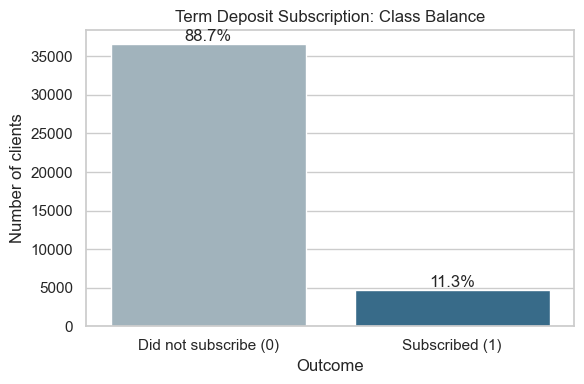

In [ ]:
# Class balance of the target
fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(data=df_clean, x='y', ax=ax, palette=['#9db4c0', '#2a6f97'])
ax.set_xticks([0, 1], ['Did not subscribe (0)', 'Subscribed (1)'])
total = len(df_clean)
for bar in ax.patches:  # annotate each bar with its share of all contacts
    ax.annotate(f'{bar.get_height() / total:.1%}', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                ha='center', va='bottom')
ax.set_title('Term Deposit Subscription: Class Balance')
ax.set_xlabel('Outcome')
ax.set_ylabel('Number of clients')
plt.tight_layout()
save_fig('class_balance')
plt.show()

Only **~11.3%** of contacts led to a subscription. The classes are heavily **imbalanced**, so accuracy alone will be a misleading metric (see Problem 7).

**How do the continuous features differ between subscribers and non-subscribers?**

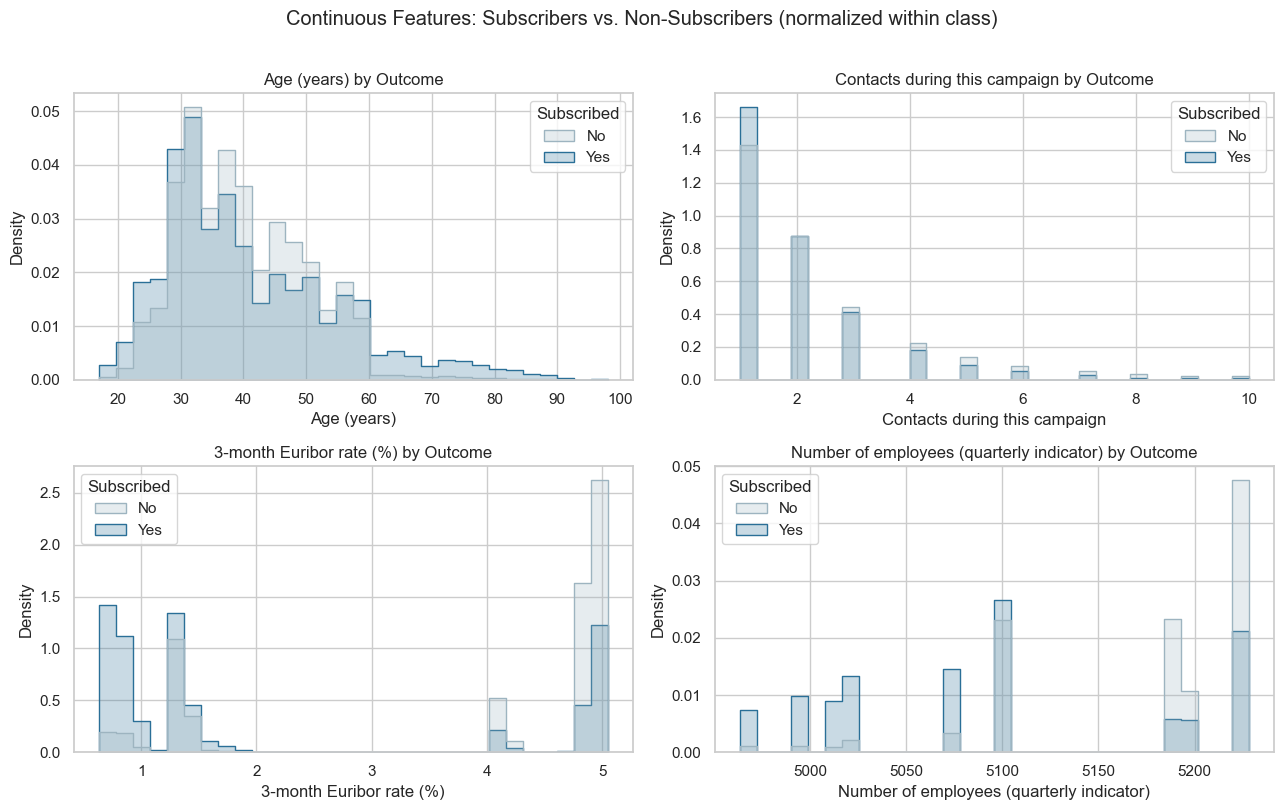

In [ ]:
# Distributions of key continuous features, split by outcome
num_plot_cols = {'age': 'Age (years)',
                 'campaign': 'Contacts during this campaign',
                 'euribor3m': '3-month Euribor rate (%)',
                 'nr.employed': 'Number of employees (quarterly indicator)'}

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (col, label) in zip(axes.flat, num_plot_cols.items()):
    data = df_clean[df_clean['campaign'] <= 10] if col == 'campaign' else df_clean  # clip long tail
    data = data.assign(Subscribed=data['y'].map({0: 'No', 1: 'Yes'}))           # readable legend
    sns.histplot(data=data, x=col, hue='Subscribed', hue_order=['No', 'Yes'], stat='density',
                 common_norm=False, element='step', bins=30, ax=ax, palette=['#9db4c0', '#2a6f97'])
    ax.set_title(f'{label} by Outcome')
    ax.set_xlabel(label)
fig.suptitle('Continuous Features: Subscribers vs. Non-Subscribers (normalized within class)', y=1.01)
plt.tight_layout()
save_fig('numeric_distributions')
plt.show()

In [ ]:
# Summary statistics of numeric features by outcome
numeric_cols = ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx',
                'cons.conf.idx', 'euribor3m', 'nr.employed']
df_clean.groupby('y')[numeric_cols].median().T.rename(columns={0: 'Median: No', 1: 'Median: Yes'}).round(2)

y,Median: No,Median: Yes
age,38.00,37.00
campaign,2.00,2.00
previous,0.00,0.00
emp.var.rate,1.10,-1.80
cons.price.idx,93.92,93.20
cons.conf.idx,-41.80,-40.40
euribor3m,4.86,1.27
nr.employed,5195.80,5099.10


**Which categories have higher subscription rates?** The dashed line marks the overall rate (~11.3%).

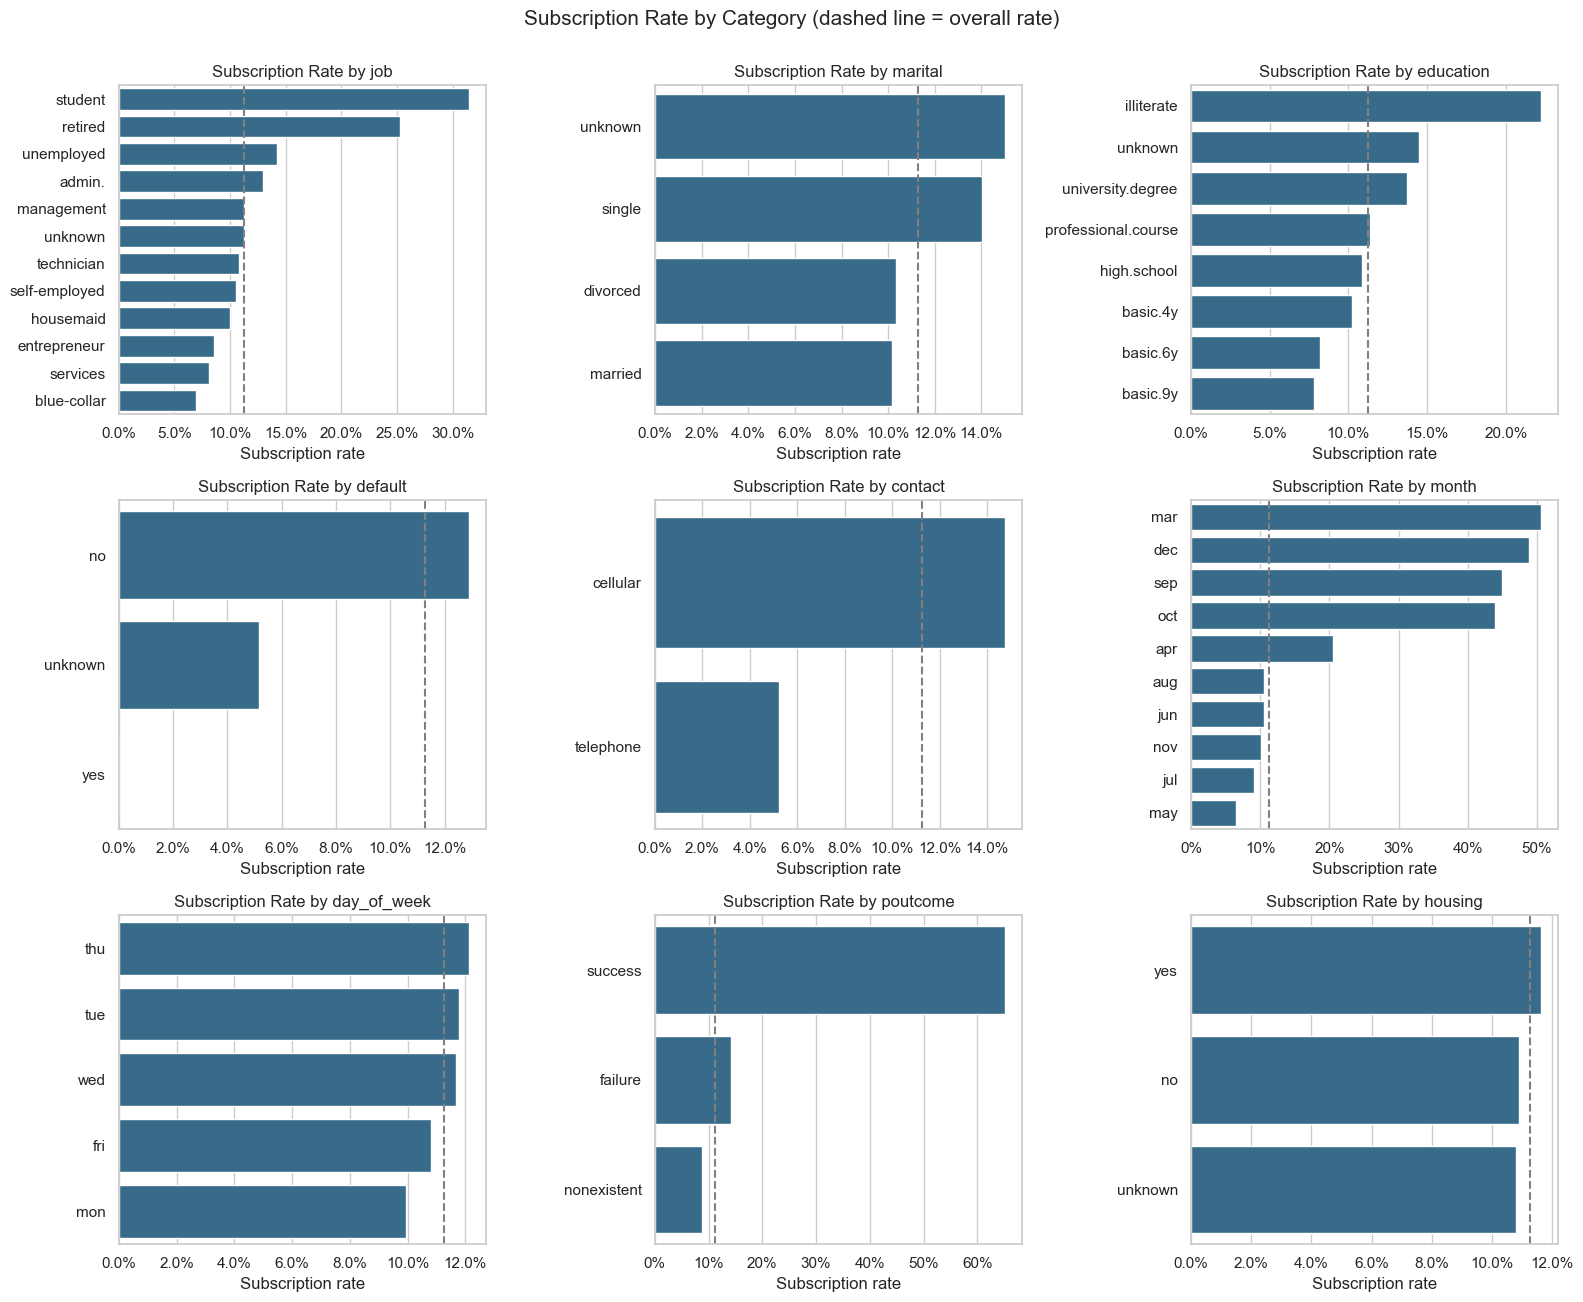

In [ ]:
# Subscription rate by category for the main categorical features
cat_plot_cols = ['job', 'marital', 'education', 'default', 'contact',
                 'month', 'day_of_week', 'poutcome', 'housing']
overall_rate = df_clean['y'].mean()

fig, axes = plt.subplots(3, 3, figsize=(16, 13))
for ax, col in zip(axes.flat, cat_plot_cols):
    rates = df_clean.groupby(col)['y'].mean().sort_values(ascending=False)
    sns.barplot(x=rates.values, y=rates.index, ax=ax, color='#2a6f97')
    ax.axvline(overall_rate, ls='--', color='gray')
    ax.set_title(f'Subscription Rate by {col}')
    ax.set_xlabel('Subscription rate')
    ax.set_ylabel('')
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
fig.suptitle('Subscription Rate by Category (dashed line = overall rate)', fontsize=15, y=1.0)
plt.tight_layout()
save_fig('categorical_rates')
plt.show()

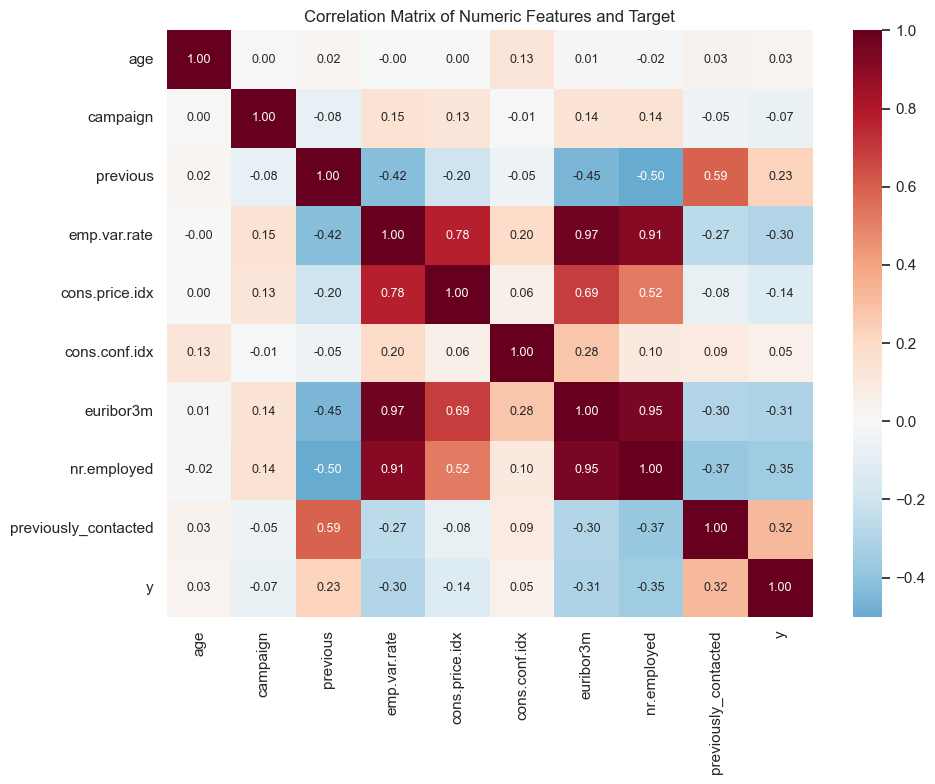

In [ ]:
# Correlation between numeric features (and the target)
corr = df_clean[numeric_cols + ['previously_contacted', 'y']].corr()
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax, annot_kws={'size': 9})
ax.set_title('Correlation Matrix of Numeric Features and Target')
plt.tight_layout()
plt.show()

#### Inferential statistics: are these differences real or chance?

- **Chi-square tests of independence** for each categorical feature vs. the target. **Cramér's V** measures the strength of each association (0 = none, 1 = perfect).
- **Mann-Whitney U tests** for the numeric features. Most of them are skewed or non-normal, so this rank-based test is safer than a t-test.

In [ ]:
# Chi-square test of independence: each categorical feature vs. subscription
chi_rows = []
for col in list(cat_cols) + ['previously_contacted']:
    table = pd.crosstab(df_clean[col], df_clean['y'])
    chi2, p_value, dof, _ = stats.chi2_contingency(table)
    cramers_v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    chi_rows.append({'feature': col, 'chi2': round(chi2, 1), 'p_value': p_value, "cramers_v": round(cramers_v, 3)})

chi_results = pd.DataFrame(chi_rows).sort_values('cramers_v', ascending=False).reset_index(drop=True)
chi_results['p_value'] = chi_results['p_value'].map(lambda p: f'{p:.1e}')
chi_results

,feature,chi2,p_value,cramers_v
0,previously_contacted,4341.3,0.0e+00,0.325
1,poutcome,4230.1,0.0e+00,0.321
2,month,3103.0,0.0e+00,0.275
3,job,961.7,3.3e-199,0.153
4,contact,862.1,1.7e-189,0.145
5,default,406.6,5.2e-89,0.099
6,education,192.8,3.7e-38,0.068
7,marital,123.0,1.8e-26,0.055
8,day_of_week,26.1,3.1e-05,0.025
9,housing,5.7,5.7e-02,0.012


In [ ]:
# Mann-Whitney U test: do numeric features differ between subscribers and non-subscribers?
mw_rows = []
for col in numeric_cols:
    yes_vals = df_clean.loc[df_clean['y'] == 1, col]
    no_vals = df_clean.loc[df_clean['y'] == 0, col]
    u_stat, p_value = stats.mannwhitneyu(yes_vals, no_vals)
    mw_rows.append({'feature': col, 'mean_yes': yes_vals.mean(), 'mean_no': no_vals.mean(),
                    'p_value': p_value,
                    # rank-biserial correlation: > 0 means subscribers tend to have higher values
                    'effect_size_r': 2 * u_stat / (len(yes_vals) * len(no_vals)) - 1})

mw_results = pd.DataFrame(mw_rows).round(3)
mw_results['p_value'] = mw_results['p_value'].map(lambda p: f'{p:.1e}')
mw_results.sort_values('effect_size_r', key=abs, ascending=False).reset_index(drop=True)

,feature,mean_yes,mean_no,p_value,effect_size_r
0,nr.employed,5095.120,5176.166,0.0e+00,-0.498
1,euribor3m,2.123,3.811,0.0e+00,-0.487
2,emp.var.rate,-1.233,0.249,0.0e+00,-0.433
3,cons.price.idx,93.355,93.604,0.0e+00,-0.221
4,previous,0.493,0.132,0.0e+00,0.219
5,campaign,2.052,2.633,0.0e+00,-0.110
6,cons.conf.idx,-39.791,-40.593,0.0e+00,0.074
7,age,40.912,39.911,1.6e-02,-0.022


**Observations from the descriptive and inferential statistics**

- **Previous relationship is the strongest signal.** Clients for whom the previous campaign was a *success* subscribed **65%** of the time. Clients never contacted before subscribed only **8.8%** of the time. `previously_contacted` and `poutcome` have the largest Cramér's V (~0.32).
- **Timing matters a lot.** May had the most calls (13,767, a third of all contacts) but the lowest success rate, **6.4%**. March, September, October and December had few calls but **44-51%** success. Part of this is seasonality. Part of it reflects *when* in 2008-2010 the bank was calling, so it should be read as a correlation, not as "call in March".
- **Channel:** clients reached on a **cell phone** subscribed at **14.7%**, versus **5.2%** for a landline.
- **Who subscribes:** **students (31%)** and **retirees (25%)** subscribe far more than average. Blue-collar workers (6.9%) and services workers subscribe the least. By age, the effect sits at the extremes: under 25 → 24%, 60 and over → 40%, 25-59 → 10%. That is why *average* age barely differs between the groups (Mann-Whitney effect size ≈ 0.02).
- **Credit history:** clients whose default status is `unknown` subscribe at only 5.2%, versus 12.9% for `no`.
- **More calls do not help.** The subscription rate falls from 13% on the first contact to about 5.5% after six or more contacts in the same campaign.
- **Economic conditions are highly predictive.** When the 3-month Euribor rate was below 2%, **24.5%** of contacts subscribed. When it was 4% or higher, only **4.8%** did. `euribor3m`, `nr.employed` and `emp.var.rate` all have large effect sizes (|r| ≈ 0.43-0.50), but they are almost perfectly correlated with each other (0.91-0.97) and describe the same economic cycle.
- **Not significant:** `housing` (p ≈ 0.06) and `loan` (p ≈ 0.58) show no meaningful relationship with subscription. `day_of_week` is statistically significant, but its effect is negligible (V = 0.025).
- *Caveat:* with ~41,000 rows almost any difference reaches p < 0.05, so I rely on the **effect sizes** (Cramér's V, rank-biserial r) to judge what matters in practice.

### Problem 5: Engineering Features

Now that you understand your business objective, we will build a basic model to get started.  Before we can do this, we must work to encode the data.  Using just the bank information features, prepare the features and target column for modeling with appropriate encoding and transformations.

In [ ]:
# Problem 5 uses only the bank client features (1-7 in the data description)
bank_features = ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan']
bank_cat_features = ['job', 'marital', 'education', 'default', 'housing', 'loan']
bank_num_features = ['age']

X_bank = df_clean[bank_features]
y = df_clean['y']

In [ ]:
# Scale the numeric column (needed for KNN, SVM and regularized logistic regression)
# and one-hot encode the nominal columns
bank_preprocessor = ColumnTransformer([
    ('num', StandardScaler(), bank_num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), bank_cat_features),
])

In [ ]:
# Quick check of the encoded feature matrix
encoded_bank = bank_preprocessor.fit_transform(X_bank)
print(f'Encoded bank-feature matrix: {encoded_bank.shape[0]:,} rows x {encoded_bank.shape[1]} columns')

Encoded bank-feature matrix: 41,176 rows x 34 columns


The preprocessing sits inside a `Pipeline` with each model, so the scaler and encoder are **fit only on the training data**. That keeps information from the test set out of training.

### Problem 6: Train/Test Split

With your data prepared, split it into a train and test set.

In [ ]:
# Stratify on the target so train and test keep the same ~11% subscription rate
X_train, X_test, y_train, y_test = train_test_split(
    X_bank, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

In [ ]:
print(f'Train: {X_train.shape[0]:,} rows | subscription rate {y_train.mean():.2%}')
print(f'Test:  {X_test.shape[0]:,} rows | subscription rate {y_test.mean():.2%}')

Train: 30,882 rows | subscription rate 11.27%
Test:  10,294 rows | subscription rate 11.27%


### Problem 7: A Baseline Model

Before we build our first model, we want to establish a baseline.  What is the baseline performance that our classifier should aim to beat?

In [ ]:
# Baseline: always predict the majority class ('no')
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
baseline_preds = baseline.predict(X_test)

print(f'Baseline test accuracy: {accuracy_score(y_test, baseline_preds):.4f}')
print(f'Baseline recall (subscribers found): {recall_score(y_test, baseline_preds):.2f}')
print(f'Baseline ROC-AUC: {roc_auc_score(y_test, baseline.predict_proba(X_test)[:, 1]):.2f}')

Baseline test accuracy: 0.8873
Baseline recall (subscribers found): 0.00
Baseline ROC-AUC: 0.50


**Baseline:** always predicting *"will not subscribe"* gives **~88.7% accuracy**, but it finds **zero** subscribers and has a ROC-AUC of 0.50 (no better than a coin flip at ranking clients). Any useful model has to **beat 88.7% accuracy** and, more importantly, do better than 0.50 at ranking likely subscribers above unlikely ones.

### Problem 8: A Simple Model

Use Logistic Regression to build a basic model on your data.  

In [ ]:
# Logistic regression on the bank client features
logreg_pipe = Pipeline([
    ('preprocess', bank_preprocessor),
    ('model', LogisticRegression(max_iter=1000)),
])
logreg_pipe.fit(X_train, y_train)

,steps,"[('preprocess', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


### Problem 9: Score the Model

What is the accuracy of your model?

In [ ]:
logreg_preds = logreg_pipe.predict(X_test)
logreg_scores = logreg_pipe.predict_proba(X_test)[:, 1]

print(f'Logistic regression test accuracy: {accuracy_score(y_test, logreg_preds):.4f}')
print(f'Recall: {recall_score(y_test, logreg_preds):.3f} | ROC-AUC: {roc_auc_score(y_test, logreg_scores):.3f}')

Logistic regression test accuracy: 0.8873
Recall: 0.000 | ROC-AUC: 0.654


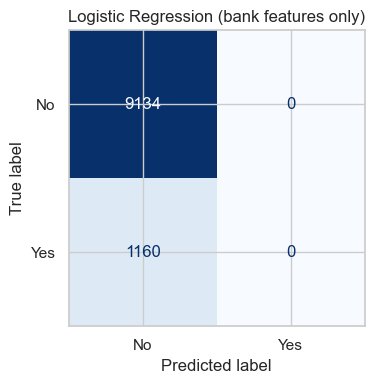

In [ ]:
# The confusion matrix shows what accuracy hides
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, logreg_preds, display_labels=['No', 'Yes'],
                                        cmap='Blues', ax=ax, colorbar=False)
ax.set_title('Logistic Regression (bank features only)')
plt.tight_layout()
plt.show()

**Interpretation:** the logistic regression scores **88.73% accuracy**, identical to the baseline. The confusion matrix shows why: it predicts *"no"* for every client and finds **0** subscribers. With only client-profile features, no client's predicted probability ever reaches the default 0.5 threshold.

The model does carry *some* ranking signal (**ROC-AUC 0.65** vs. 0.50 for the baseline), but accuracy is blind to it. This is the clearest evidence that **accuracy is the wrong metric for this problem.**

### Problem 10: Model Comparisons

Now, we aim to compare the performance of the Logistic Regression model to our KNN algorithm, Decision Tree, and SVM models.  Using the default settings for each of the models, fit and score each.  Also, be sure to compare the fit time of each of the models.  Present your findings in a `DataFrame` similar to that below:

| Model | Train Time | Train Accuracy | Test Accuracy |
| ----- | ---------- | -------------  | -----------   |
|     |    |.     |.     |

In [ ]:
def positive_scores(model, X):
    """Return a score for the positive class (probability if available, else SVM decision value)."""
    if hasattr(model, 'predict_proba'):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


default_models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'KNN': KNeighborsClassifier(),
    'Decision Tree': DecisionTreeClassifier(random_state=RANDOM_STATE),
    'SVM': SVC(),
}

default_rows = []
for name, estimator in default_models.items():
    pipe = Pipeline([('preprocess', bank_preprocessor), ('model', estimator)])
    start = time.perf_counter()
    pipe.fit(X_train, y_train)
    train_time = time.perf_counter() - start
    default_rows.append({
        'Model': name,
        'Train Time (s)': train_time,
        'Train Accuracy': accuracy_score(y_train, pipe.predict(X_train)),
        'Test Accuracy': accuracy_score(y_test, pipe.predict(X_test)),
        'Test ROC-AUC': roc_auc_score(y_test, positive_scores(pipe, X_test)),
    })

default_results = pd.DataFrame(default_rows).set_index('Model').round(4)
default_results

,Train Time (s),Train Accuracy,Test Accuracy,Test ROC-AUC
Model,,,,
Logistic Regression,0.0400,0.8873,0.8873,0.6544
KNN,0.0240,0.8919,0.8781,0.5940
Decision Tree,0.1628,0.9181,0.8626,0.5830
SVM,23.8189,0.8879,0.8874,0.5916


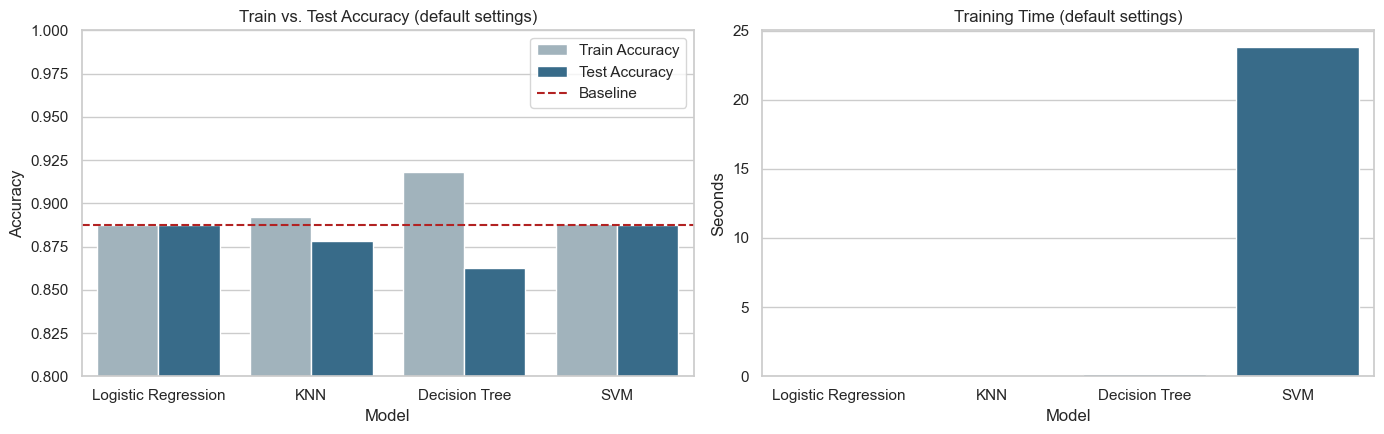

In [ ]:
# Visual comparison of the default models
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
acc_long = default_results[['Train Accuracy', 'Test Accuracy']].reset_index().melt(
    id_vars='Model', var_name='Split', value_name='Accuracy')
sns.barplot(data=acc_long, x='Model', y='Accuracy', hue='Split', ax=axes[0], palette=['#9db4c0', '#2a6f97'])
axes[0].axhline(accuracy_score(y_test, baseline_preds), ls='--', color='firebrick', label='Baseline')
axes[0].set_ylim(0.8, 1.0)
axes[0].set_title('Train vs. Test Accuracy (default settings)')
axes[0].legend(loc='upper right')

sns.barplot(x=default_results.index, y=default_results['Train Time (s)'], ax=axes[1], color='#2a6f97')
axes[1].set_title('Training Time (default settings)')
axes[1].set_ylabel('Seconds')
axes[1].set_xlabel('Model')
plt.tight_layout()
plt.show()

**Observations**

- **No default model meaningfully beats the 88.7% baseline accuracy.** Logistic regression and the SVM match it by predicting almost everyone as *no*. KNN (87.8%) and the decision tree (86.3%) actually fall **below** the baseline.
- The **decision tree overfits**: 91.8% train accuracy vs. 86.3% test accuracy. With no depth limit it memorizes the training data.
- **Training time differs a lot.** The SVM takes about 22 seconds, hundreds of times slower than the others, with no gain in performance. KNN "trains" fastest because it just stores the data, but it pays that cost at prediction time.
- ROC-AUC is only **0.58-0.65** across all models. **The seven client-profile features alone are weak predictors.** Improving the model needs better features and a better metric, not just a different algorithm.

### Problem 11: Improving the Model

Now that we have some basic models on the board, we want to try to improve these.  Below, we list a few things to explore in this pursuit.


- Hyperparameter tuning and grid search.  All of our models have additional hyperparameters to tune and explore.  For example the number of neighbors in KNN or the maximum depth of a Decision Tree.  
- Adjust your performance metric

#### 11a. Choosing the evaluation metric

**Primary metric: ROC-AUC.** Supporting metrics: **recall**, **precision**, **F1** and **average precision (PR-AUC)**.

**Why not accuracy?** With ~89% "no" answers, a model that never predicts "yes" scores 88.7% accuracy and is useless (Problems 7 and 9).

**Why ROC-AUC?** The bank does not need a hard yes/no for each client. It needs to **rank clients** so that a fixed calling budget goes to the clients most likely to subscribe. ROC-AUC measures exactly that: the probability that a randomly chosen subscriber is ranked above a randomly chosen non-subscriber. It does not depend on the decision threshold, and it is not inflated by class imbalance.

**Why also recall and precision?** Once a call threshold is chosen, the trade-off is concrete. A **missed subscriber** (false negative) is lost revenue. A **wasted call** (false positive) costs a few minutes of agent time. For a term-deposit product a missed sale usually costs more than an extra call, so recall matters more, but precision keeps the call list efficient.

#### 11b. Feature engineering

Problem 10 showed that the seven client-profile features carry little signal (ROC-AUC ~0.6). For the improved models I use **every feature that is known before the call**:
- contact details (`contact`, `month`, `day_of_week`, `campaign`)
- previous-campaign history (`previous`, `poutcome`, the new `previously_contacted` flag)
- the economic context indicators.

`duration` stays excluded because of leakage.

*Note:* this dataset has no gender feature, so there is nothing to keep or drop on that point. Some features, such as `age` and `marital`, are personal attributes, and any production use should be reviewed for fairness.

In [ ]:
# Full feature set: everything known before the call (duration already removed)
all_features = df_clean.columns.drop('y').tolist()
cat_features = df_clean[all_features].select_dtypes(include='object').columns.tolist()
num_features = [c for c in all_features if c not in cat_features]

X_full = df_clean[all_features]
X_train_full, X_test_full, y_train, y_test = train_test_split(
    X_full, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)

full_preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
])
print(f'{len(num_features)} numeric + {len(cat_features)} categorical features '
      f'-> {full_preprocessor.fit(X_train_full).transform(X_train_full).shape[1]} encoded columns')

9 numeric + 10 categorical features -> 62 encoded columns


#### 11c. Hyperparameter tuning with grid search and cross-validation

Each model is tuned with `GridSearchCV`, using **5-fold stratified cross-validation** and **ROC-AUC** as the scoring metric. The grids include `class_weight='balanced'` where the model supports it, to counter the class imbalance.

The SVM's training time grows roughly with the square of the number of rows, so it is tuned on a stratified sample of 8,000 training rows with 3-fold CV. It is still evaluated on the full test set.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

search_space = {
    'Logistic Regression': (LogisticRegression(max_iter=2000),
                            {'model__C': [0.01, 0.1, 1, 10],
                             'model__class_weight': [None, 'balanced']}),
    'KNN': (KNeighborsClassifier(),
            {'model__n_neighbors': [5, 25, 51, 101],
             'model__weights': ['uniform', 'distance']}),
    'Decision Tree': (DecisionTreeClassifier(random_state=RANDOM_STATE),
                      {'model__max_depth': [3, 5, 7, 10],
                       'model__min_samples_leaf': [1, 20, 50],
                       'model__criterion': ['gini', 'entropy'],
                       'model__class_weight': [None, 'balanced']}),
    'SVM': (SVC(),
            {'model__C': [0.1, 1, 10],
             'model__class_weight': [None, 'balanced']}),
}

# Stratified sample for the (slow) SVM grid search
X_train_svm, _, y_train_svm, _ = train_test_split(
    X_train_full, y_train, train_size=8000, stratify=y_train, random_state=RANDOM_STATE)

In [ ]:
tuned_models, tuned_rows = {}, []
for name, (estimator, grid) in search_space.items():
    pipe = Pipeline([('preprocess', full_preprocessor), ('model', estimator)])
    X_fit, y_fit, folds = (X_train_svm, y_train_svm, 3) if name == 'SVM' else (X_train_full, y_train, cv)
    search = GridSearchCV(pipe, grid, scoring='roc_auc', cv=folds, n_jobs=-1)

    start = time.perf_counter()
    search.fit(X_fit, y_fit)
    search_time = time.perf_counter() - start

    best = search.best_estimator_
    tuned_models[name] = best
    test_preds = best.predict(X_test_full)
    test_scores = positive_scores(best, X_test_full)
    tuned_rows.append({
        'Model': name,
        'Best Params': {k.replace('model__', ''): v for k, v in search.best_params_.items()},
        'Search Time (s)': search_time,
        'CV ROC-AUC': search.best_score_,
        'Test ROC-AUC': roc_auc_score(y_test, test_scores),
        'Test PR-AUC': average_precision_score(y_test, test_scores),
        'Test Accuracy': accuracy_score(y_test, test_preds),
        'Test Recall': recall_score(y_test, test_preds),
        'Test Precision': precision_score(y_test, test_preds),
        'Test F1': f1_score(y_test, test_preds),
    })

tuned_results = pd.DataFrame(tuned_rows).set_index('Model').sort_values('Test ROC-AUC', ascending=False)
tuned_results.drop(columns='Best Params').round(3)

,Search Time (s),CV ROC-AUC,Test ROC-AUC,Test PR-AUC,Test Accuracy,Test Recall,Test Precision,Test F1
Model,,,,,,,,
Logistic Regression,5.015,0.789,0.802,0.443,0.832,0.641,0.361,0.462
Decision Tree,6.224,0.783,0.798,0.449,0.900,0.262,0.636,0.371
KNN,6.472,0.778,0.795,0.448,0.900,0.213,0.675,0.324
SVM,7.365,0.769,0.790,0.382,0.843,0.636,0.383,0.478


In [ ]:
# Best hyperparameters found for each model
for name, params in tuned_results['Best Params'].items():
    print(f'{name:<20} {params}')

Logistic Regression  {'C': 0.1, 'class_weight': 'balanced'}
Decision Tree        {'class_weight': None, 'criterion': 'entropy', 'max_depth': 7, 'min_samples_leaf': 50}
KNN                  {'n_neighbors': 101, 'weights': 'uniform'}
SVM                  {'C': 1, 'class_weight': 'balanced'}


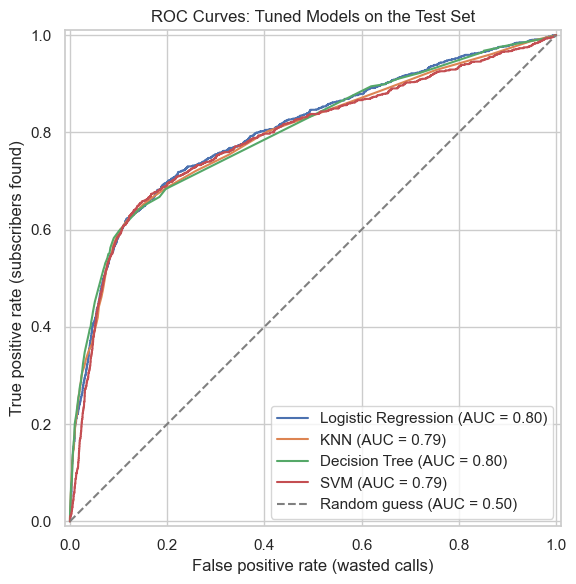

In [ ]:
# ROC curves of the tuned models on the test set
fig, ax = plt.subplots(figsize=(7, 6))
for name, model in tuned_models.items():
    RocCurveDisplay.from_predictions(y_test, positive_scores(model, X_test_full), name=name, ax=ax)
ax.plot([0, 1], [0, 1], ls='--', color='gray', label='Random guess (AUC = 0.50)')
ax.set_title('ROC Curves: Tuned Models on the Test Set')
ax.set_xlabel('False positive rate (wasted calls)')
ax.set_ylabel('True positive rate (subscribers found)')
ax.legend(loc='lower right')
plt.tight_layout()
save_fig('roc_curves')
plt.show()

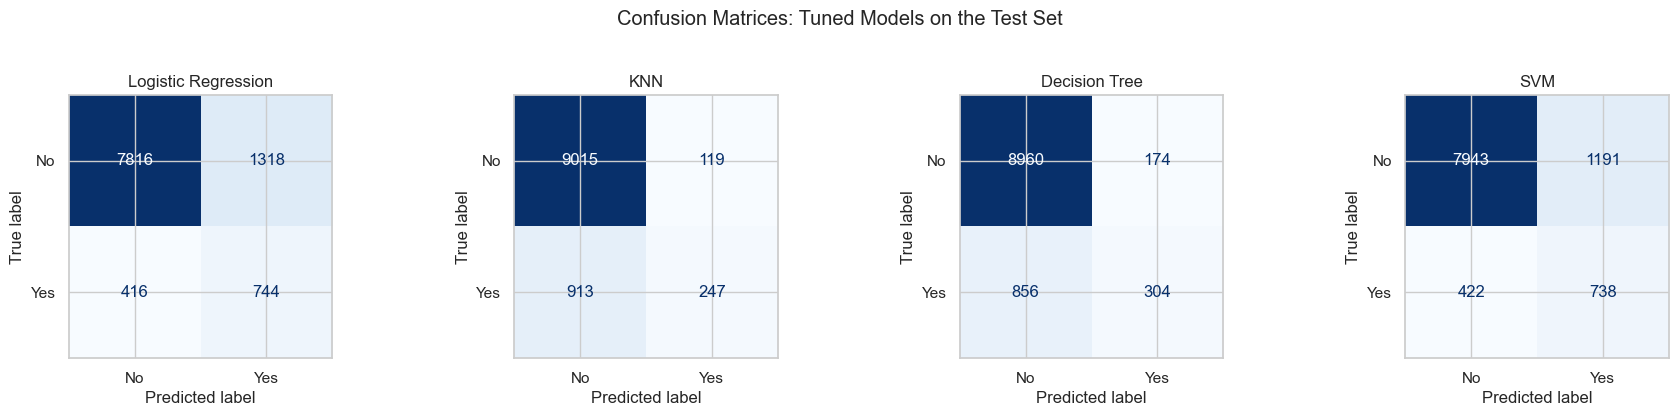

In [ ]:
# Confusion matrices at each model's default decision threshold
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (name, model) in zip(axes, tuned_models.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, model.predict(X_test_full), display_labels=['No', 'Yes'],
                                            cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(name)
fig.suptitle('Confusion Matrices: Tuned Models on the Test Set', y=1.03)
plt.tight_layout()
plt.show()

**Observations on the tuned models**

- **All four models improved substantially:** test ROC-AUC rose from 0.58-0.65 to **0.79-0.80**. Most of that gain came from adding the contact, previous-campaign and economic features. The choice of algorithm mattered much less than the choice of features.
- **Logistic regression is the best model**, with the highest test ROC-AUC (**0.802**). Its CV score (0.789) is close to its test score, so it is not overfitting. The whole grid search took about 5 seconds, it produces probabilities, and its coefficients are directly interpretable.
- **Accuracy vs. usefulness:** the tuned decision tree and KNN reach **90% accuracy**, but at the default threshold they find only **21-26%** of subscribers. Logistic regression with `class_weight='balanced'` has a lower accuracy (83%) but finds **64%** of subscribers. Roughly 1 in 3 of its "yes" calls (36% precision) converts, versus about 1 in 9 for random calling. This trade-off is deliberate, and it is why I don't use accuracy to pick the winner.
- The **SVM** had comparable ROC-AUC, but it was the slowest even on an 8,000-row sample and had the lowest PR-AUC. It gives no benefit here.

#### 11d. What does the best model mean for the calling campaign?

A **cumulative gains chart** answers the business question directly: *if we call only the top X% of clients ranked by the model, what share of all subscribers do we reach?*

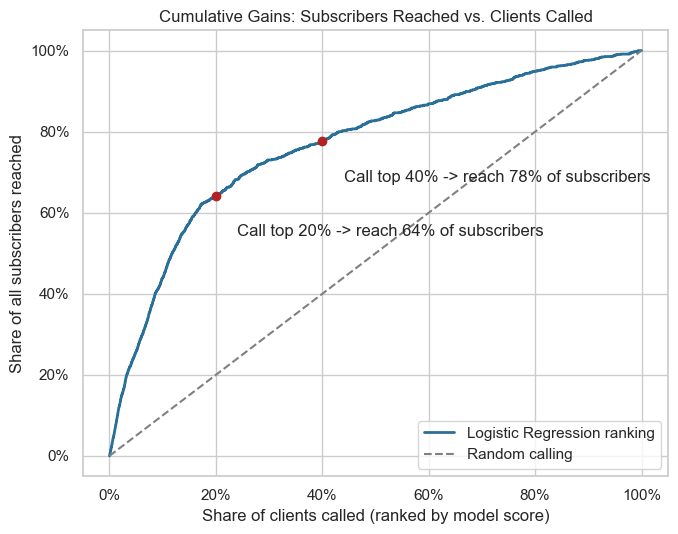

In [ ]:
# Cumulative gains for the best model vs. random calling
best_name = tuned_results.index[0]
best_model = tuned_models[best_name]
gains = (pd.DataFrame({'score': positive_scores(best_model, X_test_full), 'y': y_test.values})
           .sort_values('score', ascending=False)
           .assign(pct_called=lambda d: np.arange(1, len(d) + 1) / len(d),
                   pct_captured=lambda d: d['y'].cumsum() / d['y'].sum()))

fig, ax = plt.subplots(figsize=(7, 5.5))
ax.plot(gains['pct_called'], gains['pct_captured'], label=f'{best_name} ranking', color='#2a6f97', lw=2)
ax.plot([0, 1], [0, 1], ls='--', color='gray', label='Random calling')
for share in [0.2, 0.4]:  # highlight two possible call budgets
    captured = gains.loc[gains['pct_called'] <= share, 'pct_captured'].iloc[-1]
    ax.scatter(share, captured, color='firebrick', zorder=3)
    ax.annotate(f'Call top {share:.0%} -> reach {captured:.0%} of subscribers',
                (share, captured), xytext=(share + 0.04, captured - 0.10))
ax.set_title('Cumulative Gains: Subscribers Reached vs. Clients Called')
ax.set_xlabel('Share of clients called (ranked by model score)')
ax.set_ylabel('Share of all subscribers reached')
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.legend(loc='lower right')
plt.tight_layout()
save_fig('cumulative_gains')
plt.show()

In [ ]:
# Precision / recall trade-off at different call-list sizes
budget_rows = []
for share in [0.1, 0.2, 0.3, 0.4, 0.5]:
    top = gains[gains['pct_called'] <= share]
    budget_rows.append({'Share of clients called': f'{share:.0%}',
                        'Subscribers reached (recall)': f"{top['y'].sum() / gains['y'].sum():.1%}",
                        'Success rate per call (precision)': f"{top['y'].mean():.1%}",
                        'Lift vs. random': round(top['y'].mean() / gains['y'].mean(), 2)})
pd.DataFrame(budget_rows)

,Share of clients called,Subscribers reached (recall),Success rate per call (precision),Lift vs. random
0,10%,44.0%,49.6%,4.40
1,20%,64.1%,36.2%,3.21
2,30%,73.0%,27.4%,2.43
3,40%,77.6%,21.9%,1.94
4,50%,82.8%,18.7%,1.66


**Interpretation:** ranking clients with the logistic regression model makes each call far more productive.

- Calling only the **top 10%** of clients reaches **44%** of all subscribers, with **~50%** of those calls succeeding. That is **4.4×** better than random calling.
- Calling the **top 20%** reaches **64%** of subscribers at a 36% success rate (3.2×).
- Calling the **top 40%** still reaches **78%** of subscribers while avoiding 60% of the calls.

The bank can choose the cut-off that fits its call-center capacity and its cost per call vs. value per deposit.

#### 11e. Interpreting the models: which factors drive subscription?

**Logistic regression coefficients.** All numeric inputs are standardized, so each numeric coefficient is the change in the *log-odds* of subscribing for a one-standard-deviation increase. For one-hot categories, the coefficient compares that category with the average of its group. Exponentiating a coefficient gives an **odds ratio**: values above 1 raise the odds of subscribing, values below 1 lower them.

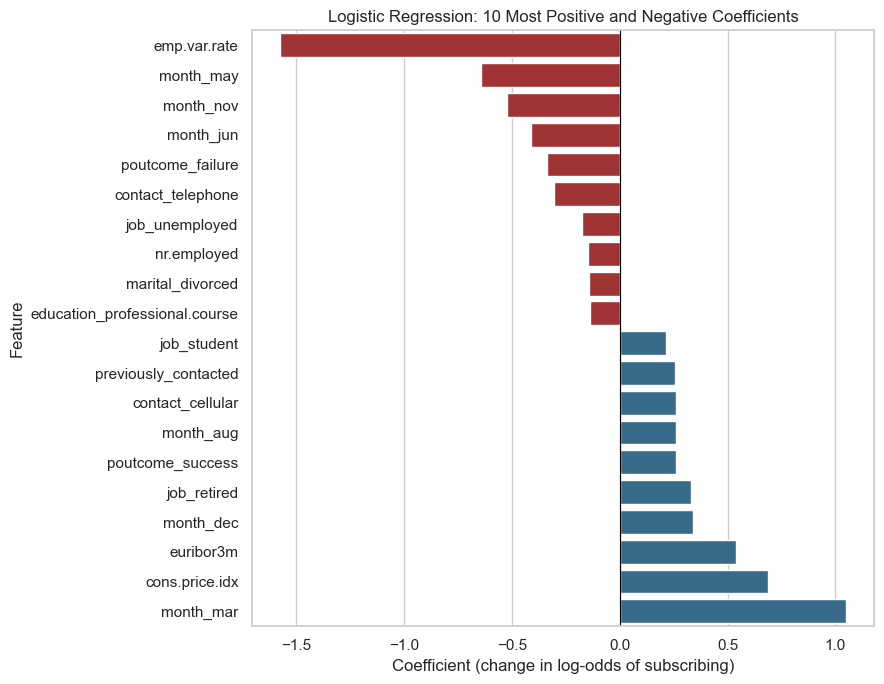

In [ ]:
# Extract logistic regression coefficients with readable feature names
logreg_best = tuned_models['Logistic Regression']
feature_names = logreg_best.named_steps['preprocess'].get_feature_names_out()
feature_names = [f.replace('num__', '').replace('cat__', '') for f in feature_names]
coefs = pd.Series(logreg_best.named_steps['model'].coef_[0], index=feature_names)

top_coefs = pd.concat([coefs.nlargest(10), coefs.nsmallest(10)]).sort_values()
fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(x=top_coefs.values, y=top_coefs.index, ax=ax,
            palette=['firebrick' if v < 0 else '#2a6f97' for v in top_coefs.values])
ax.axvline(0, color='black', lw=0.8)
ax.set_title('Logistic Regression: 10 Most Positive and Negative Coefficients')
ax.set_xlabel('Coefficient (change in log-odds of subscribing)')
ax.set_ylabel('Feature')
plt.tight_layout()
save_fig('logreg_coefficients')
plt.show()

In [ ]:
# Odds ratios for the strongest effects
odds = pd.DataFrame({'coefficient': top_coefs, 'odds_ratio': np.exp(top_coefs)}).round(2)
odds.sort_values('coefficient', ascending=False)

,coefficient,odds_ratio
month_mar,1.05,2.85
cons.price.idx,0.69,1.99
euribor3m,0.54,1.72
month_dec,0.34,1.40
job_retired,0.33,1.39
previously_contacted,0.26,1.29
poutcome_success,0.26,1.30
month_aug,0.26,1.30
contact_cellular,0.26,1.30
job_student,0.22,1.24


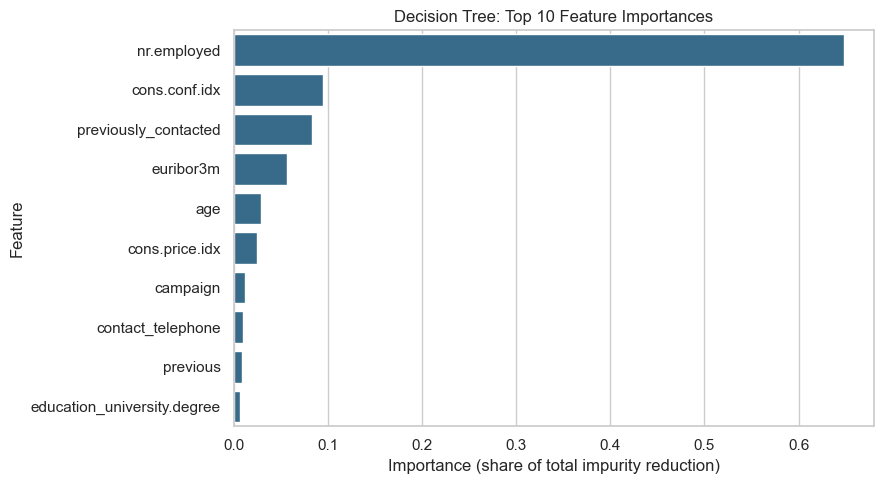

In [ ]:
# Decision tree feature importances (total impurity reduction per feature)
tree_best = tuned_models['Decision Tree']
importances = pd.Series(tree_best.named_steps['model'].feature_importances_, index=feature_names)
top_imp = importances.nlargest(10)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=top_imp.values, y=top_imp.index, ax=ax, color='#2a6f97')
ax.set_title('Decision Tree: Top 10 Feature Importances')
ax.set_xlabel('Importance (share of total impurity reduction)')
ax.set_ylabel('Feature')
plt.tight_layout()
plt.show()

**Interpreting the coefficients (logistic regression) and importances (decision tree)**

- **Previous relationship:** `poutcome_success` (odds ratio 1.30) and `previously_contacted` (1.29) both raise the odds of subscribing, and their effects add up for a client who said yes last time. `poutcome_failure` lowers the odds (0.71).
- **Contact channel:** cellular (OR 1.30) vs. telephone (OR 0.74). Holding everything else equal, a client reached by cell phone has roughly **1.8×** the odds of subscribing (e^(0.26+0.31) ≈ 1.77).
- **Month:** March (OR 2.85) is the strongest positive month. May (0.53), November (0.59) and June (0.66) are the most negative. This matches the EDA.
- **Client type:** retirees (OR 1.39) and students (OR 1.24) are more likely to subscribe. Unemployed clients are less likely (0.84).
- **Economic indicators:** `emp.var.rate` has the single largest coefficient (OR 0.21 per standard deviation): a growing economy means fewer subscriptions. `euribor3m` and `cons.price.idx` get *positive* coefficients even though, on their own, lower Euribor rates go with more subscriptions. This is **multicollinearity**: the economic indicators are 0.91-0.97 correlated, so the model splits one shared effect across them, and the individual signs should not be read in isolation. Taken together, they say that **clients subscribe more when the economy is weak and interest rates are low.**
- The **decision tree** (depth 7) agrees with this picture. `nr.employed` alone accounts for **~65%** of its total importance, followed by consumer confidence (~10%), `previously_contacted` (~8%) and the Euribor rate (~6%). Age, number of calls and contact channel play smaller roles. Both models point to the same three drivers: **economic conditions, previous relationship, and how and when the client is contacted.**

##### Questions

## Findings

### Business understanding
The bank wants to sell term deposits by phone, but only **~11% of calls succeed**. Every unsuccessful call costs agent time and goodwill. The goal was to predict, **before dialing**, which clients are likely to subscribe, so the bank can spend its calling budget on them. Four classifiers were compared: k-nearest neighbors, logistic regression, decision tree and support vector machine.

### How the models were judged
Accuracy is misleading here. A "model" that says *nobody will subscribe* is 88.7% accurate and completely useless. I used **ROC-AUC** instead. It measures how well a model **ranks** likely subscribers above unlikely ones, which is exactly what a call list needs. I also report **recall** (share of subscribers we reach) and **precision** (share of calls that succeed).

`duration` (call length) was removed because it is only known after the call ends. Keeping it would make the model look much better than it could ever be in practice.

### Model comparison

| Model | Test ROC-AUC (tuned) | Subscribers found (recall) | Calls that succeed (precision) | Comment |
|---|---|---|---|---|
| **Logistic Regression** | **0.802** | **64%** | 36% | Best ranking, fastest, easy to explain → **recommended** |
| Decision Tree | 0.798 | 26% | 64% | Close second, produces simple rules |
| KNN | 0.795 | 21% | 68% | Good ranking, but slow to predict at scale |
| SVM | 0.790 | 64% | 38% | Slowest to train, no extra benefit |

Using only basic client details (age, job, education and so on), no model did better than guessing "no" for everyone. **Adding information about the contact, the client's history with past campaigns and the economy raised performance from ~0.65 to ~0.80 ROC-AUC.** That gain was far larger than any difference between the algorithms.

### Key insights for the marketing team
1. **Calling the model's top-ranked clients is much more efficient.** Calling just the **top 20%** of clients reaches **~64% of all subscribers**, and about **1 in 3 calls succeeds**, compared with about 1 in 9 when calling at random. Calling the top 10% reaches 44% of subscribers at a ~50% success rate.
2. **Past customers who said yes are the best prospects.** **65%** of clients who accepted a previous campaign offer subscribed again, versus under 9% of clients never contacted before.
3. **Call mobile phones.** Clients reached on a cell phone subscribed about **3×** as often as landline contacts (14.7% vs. 5.2%).
4. **Students and retirees respond best** (31% and 25% vs. 11% overall). Blue-collar and services workers respond least.
5. **Stop after a few attempts.** Success drops from 13% on the first call to about 5% after six or more calls to the same person in one campaign.
6. **The economy matters.** Clients were far more receptive when interest rates were low and the job market was weak (24.5% success when the Euribor rate was under 2%, vs. 4.8% when it was 4% or higher). Campaign targets should be adjusted to economic conditions.
7. **Some things do not matter:** whether a client has a housing or personal loan, and the day of the week, had little or no effect on the outcome.

### Actionable recommendations
- **Score every client with the logistic regression model before each campaign and call in order of score.** Set the cut-off (for example, the top 20-30%) to match call-center capacity.
- **Prioritize previous successful customers and mobile numbers**, and collect mobile numbers where they are missing.
- **Cap repeat calls** at about 3 per client per campaign, and use the freed-up time on new high-scoring clients.
- **Tailor the offer and script** for the strongest segments: retirees (security and income) and students (first savings product).
- **Scale campaigns up when interest rates are low** and expect lower conversion when rates rise.

### Next steps
- **Pick the threshold from costs:** estimate the cost of a call and the value of a deposit, then choose the cut-off that maximizes expected profit instead of a fixed percentage.
- **Try stronger models:** test ensemble methods (random forest, gradient boosting) and probability calibration. Report any improvement in ROC-AUC alongside the interpretability lost.
- **Validate over time:** train on earlier campaigns and test on later ones, to make sure the model holds up as economic conditions change. The month and economic features are tied to 2008-2010.
- **Run a controlled pilot (A/B test):** call one group by model score and one group as usual, and measure the real lift in subscriptions per call.
- **Review fairness:** personal attributes such as age and marital status influence predictions. Make sure targeting complies with regulations and treats customers fairly.
- **Retrain regularly** as new campaign results come in.
